In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
import seaborn

import os
import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.21.5


In [2]:
if 1:
    import importlib
    importlib.reload(util);


In [3]:
df2tex = util.df2tex

In [4]:
weighted = 0


folder = '../data_out/'
tree_alg = 'GMM' # 'stat', 'GMM', 'RF', '4class'
mode = 'all_assoc' # 'all_assoc', 'no_bcu_spp'
if mode == 'all_assoc':
    mode_str = ''
else:
    mode_str = '_%s' % mode
feature_mode = 'all features' # 'all features', 'no coord features'

if tree_alg == 'GMM':
    nmin = 100
    tree_cat_fn = folder + 'tree_cat_nmin%i.yaml' % nmin
if tree_alg == 'RF':
    if mode == 'no_bcu_spp':
        nmin = 60
    else:
        nmin = 100
    tree_cat_fn = folder + 'tree_cat_nmin%i_RF%s.yaml' % (nmin, mode_str)
elif tree_alg == 'stat':
    tree_cat_fn = folder + 'tree_cat_stat.yaml'
elif tree_alg == 'RF_aakash':
    tree_cat_fn = folder + 'tree_cat_rf_15_50.yaml'
elif tree_alg == '4class':
    tree_cat_fn = folder + 'tree_cat_4class.yaml'
elif tree_alg == '2class':
    tree_cat_fn = folder + 'tree_cat_2class_gal_egal.yaml'
    title_dict = {'00': 'Extragalactic', '01': 'Galactic'}

tree_cat_dict = dio3.loaddict(tree_cat_fn)
nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

alg_descr = '_%s' % tree_alg
if tree_alg == 'GMM' or tree_alg == 'RF':
    alg_descr += '_nmin%s' % (nmin)
elif tree_alg == '2class':
    alg_descr += '_gal_egal'
alg_descr += mode_str
if feature_mode == 'no coord features':
    alg_descr += '_no_coord_features'

if weighted:
    weight_str = '_weighted'
else:
    weight_str = ''

folder_res = '../results/4FGL-DR3_probabilistic_classification_weighted/'
fn = folder_res + '4FGL-DR3_%iclass%s%s_prob_cat.csv' % (nclasses, alg_descr, weight_str)
summary_fn = folder_res + '4FGL-DR3_%iclass%s%s_summary.csv' % (nclasses, alg_descr, weight_str)


cat_df = pd.read_csv(fn, index_col=0)
algs = ['RF', 'NN']
unas_mask = (cat_df['CLASS1'] == 'unas') | (cat_df['CLASS1'] == 'unk')
ns = len(cat_df)

In [5]:
sum(cat_df['CLASS1'] == 'unas')

2157

In [6]:
pcols = [cl for cl in cat_df.columns if cl[-2:] in algs]

In [7]:
cat_df.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', '1_RF',
       '1_RF_std', '1_NN', '1_NN_std', '2_RF', '2_RF_std', '2_NN', '2_NN_std',
       '3_RF', '3_RF_std', '3_NN', '3_NN_std', '4_RF', '4_RF_std', '4_NN',
       '4_NN_std', '5_RF', '5_RF_std', '5_NN', '5_NN_std', '6_RF', '6_RF_std',
       '6_NN', '6_NN_std', 'sample_weight'],
      dtype='object')

In [8]:
src = []
for node in nodes:
    dfc = 0.
    for alg in algs:
        cl = '%s_%s' % (node, alg)
        dfc += cat_df[cl][unas_mask] / len(algs)
    dfc = dfc.sort_values(ascending=False)
    src.extend(dfc.index[:1])

In [9]:
len(src)

6

In [10]:
cols = ['Source_Name', 'Group', 'RF prob', 'NN prob']
df_out = pd.DataFrame(columns=cols, index=range(len(src)))
i = 0
for node in nodes:
    for j in range(1):
        df_out['Group'].iloc[i] = util.cl_list2str(dec_tree_cat_dict[int(node)])
        df_out['Source_Name'].iloc[i] = src[i]
        for alg in algs:
            df_out['%s prob' % alg].iloc[i] = cat_df['%s_%s' % (node, alg)][src[i]]
        i += 1

In [11]:
df_out.index = range(1, len(df_out) + 1)

In [12]:
df_out

,Source_Name,Group,RF prob,NN prob
1,4FGL J0259.0+0552,"sbg, rdg, bll, css",0.849643,0.910161
2,4FGL J0852.2-7208,"bcu, ssrq",0.879289,0.848527
3,4FGL J0427.3+0504,"fsrq, sey, nlsy1, agn",0.741902,0.850338
4,4FGL J1424.2-6111c,"glc, nov, spp",0.764772,0.660677
5,4FGL J1602.2+2305,"msp, lmb",0.861336,0.947061
6,4FGL J1553.8-5325e,"hmb, psr, sfr, snr, gc, pwn, gal, bin",0.892897,0.89423


In [13]:
print(df2tex(df_out, fmt='%.3f', index=False))

\begin{tabular}{llll}
\hline
       Source\_Name &                                 Group & RF prob & NN prob \\
\hline
 4FGL J0259.0+0552 &                    sbg, rdg, bll, css &   0.850 &   0.910 \\
 4FGL J0852.2-7208 &                             bcu, ssrq &   0.879 &   0.849 \\
 4FGL J0427.3+0504 &                 fsrq, sey, nlsy1, agn &   0.742 &   0.850 \\
4FGL J1424.2-6111c &                         glc, nov, spp &   0.765 &   0.661 \\
 4FGL J1602.2+2305 &                              msp, lmb &   0.861 &   0.947 \\
4FGL J1553.8-5325e & hmb, psr, sfr, snr, gc, pwn, gal, bin &   0.893 &   0.894 \\
\hline
\end{tabular}



In [14]:
print(df2tex(cat_df[pcols].loc[src], fmt='%.3f', index=True, index_name='Source\_Name'))

\begin{tabular}{lrrrrrrrrrrrr}
\hline
Source\_Name &  1\_RF &  1\_NN &  2\_RF &  2\_NN &  3\_RF &  3\_NN &  4\_RF &  4\_NN &  5\_RF &  5\_NN &  6\_RF &  6\_NN \\
\hline
4FGL J0259.0+0552  & 0.850 & 0.910 & 0.102 & 0.069 & 0.046 & 0.020 & 0.000 & 0.000 & 0.002 & 0.001 & 0.000 & 0.000 \\
4FGL J0852.2-7208  & 0.088 & 0.068 & 0.879 & 0.849 & 0.025 & 0.016 & 0.006 & 0.050 & 0.000 & 0.003 & 0.001 & 0.014 \\
4FGL J0427.3+0504  & 0.086 & 0.005 & 0.169 & 0.143 & 0.742 & 0.850 & 0.000 & 0.000 & 0.000 & 0.000 & 0.003 & 0.000 \\
4FGL J1424.2-6111c & 0.003 & 0.001 & 0.077 & 0.086 & 0.003 & 0.002 & 0.765 & 0.661 & 0.035 & 0.064 & 0.117 & 0.187 \\
4FGL J1602.2+2305  & 0.028 & 0.026 & 0.064 & 0.016 & 0.007 & 0.007 & 0.034 & 0.002 & 0.861 & 0.947 & 0.006 & 0.002 \\
4FGL J1553.8-5325e & 0.026 & 0.007 & 0.007 & 0.006 & 0.004 & 0.001 & 0.051 & 0.039 & 0.019 & 0.053 & 0.893 & 0.894 \\
\hline
\end{tabular}



In [15]:
# summary of predictions

nsrc_fn = '../data_out/nsrc_dict.yaml'
nsrc_dict = dio3.loaddict(nsrc_fn)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

clms = ['Node', 'Physical classes', 'N assoc']
for alg in algs:
    clms.append('%s assoc' % alg)
for alg in algs:
    clms.append('%s unas' % alg)
sdf = pd.DataFrame(columns=clms, index=range(nclasses))
for i, node in enumerate(nodes):
    cls = dec_tree_cat_dict[int(node)]
    sdf['Physical classes'].iloc[i] = util.cl_list2str(cls)
    bnode = list(max_tree_cat_dict.keys())[i]
    sdf['Node'].iloc[i] = bnode
sdf.index = range(1, len(sdf) + 1)

if 0:
    #sdf.index.name = 'Index'
    out_clms = ['Node', 'Classes']
    print(sdf[out_clms])
    tst = util.df2tex(sdf[out_clms], fmt='%.1f', index=True, index_name='')
    print(tst)
    
clf_mask = (cat_df['CLASS1'] != 'unas') & (cat_df['CLASS1'] != 'unk')
for i, node in enumerate(nodes):
    cls = dec_tree_cat_dict[int(node)]
    bnode = list(max_tree_cat_dict.keys())[i]
    sdf['Node'].iloc[i] = bnode
    nsrc = np.sum([nsrc_dict[cl] for cl in cls])
    sdf['N assoc'].iloc[i] = '%i' % nsrc
    for alg in algs:
        nas = np.sum(cat_df[clf_mask]['%s_%s' % (node, alg)])
        nas_std = cat_df[clf_mask]['%s_%s_std' % (node, alg)]
        nas_std = np.sqrt(np.sum(nas_std**2))                                   
        nunas = np.sum(cat_df[~clf_mask]['%s_%s' % (node, alg)])
        nunas_std = cat_df[~clf_mask]['%s_%s_std' % (node, alg)]
        nunas_std = np.sqrt(np.sum(nunas_std**2))

        sdf['%s assoc' % alg].iloc[i] = '$%.1f\pm %.1f$' % (nas, nas_std)
        sdf['%s unas' % alg].iloc[i] = '$%.1f\pm %.1f$' % (nunas, nunas_std)
#print(sdf)

In [16]:
np.mean(cat_df[~clf_mask]['%s_%s_std' % (node, alg)])

0.031240844264674394

In [17]:
if 1:
    max_classes = [util.get_max_class(dec_tree_cat_dict[int(key)], nsrc_df) + '+' for key in nodes]
    sdf.insert(0, 'Class label', max_classes)


In [28]:
# class definition columns
cdef_clms = ['Class label', 'Physical classes', 'N assoc']
txt = util.df2tex(sdf[cdef_clms], fmt='%.1f', index=False, index_name='')
txt = txt.replace('N assoc', 'Number of associated sources')
print(txt)

\begin{tabular}{lll}
\hline
Class label &                      Physical classes & Number of associated sources \\
\hline
       bll+ &                    sbg, rdg, bll, css &    1514 \\
       bcu+ &                             bcu, ssrq &    1495 \\
      fsrq+ &                 fsrq, sey, nlsy1, agn &     813 \\
       spp+ &                         glc, nov, spp &     153 \\
       msp+ &                              msp, lmb &     163 \\
       psr+ & hmb, psr, sfr, snr, gc, pwn, gal, bin &     229 \\
\hline
\end{tabular}



In [18]:
save_res = True
if save_res:
    print('Save predictions summary to file:')
    print(summary_fn)
    sdf.to_csv(summary_fn, index_label='Group')


Save predictions summary to file:
../results/4FGL-DR3_probabilistic_classification_weighted/4FGL-DR3_6class_GMM_nmin100_summary.csv


In [19]:
#tst = util.df2tex(sdf, fmt='%.1f', index=True, index_name='')
out_clms = list(sdf.columns)
out_clms.remove('Node')
out_clms.remove('Physical classes')
tst = util.df2tex(sdf[out_clms], fmt='%s', index=True, index_name='')
#tst = util.df2tex(sdf, fmt='%s', index=True, index_name='')
tst = tst.replace('_', '\_')
tst = tst.replace('\$', '$')
tst = tst.replace('\\textbackslash ', '\\')
while '  ' in tst:
    tst = tst.replace('  ', ' ')
if weighted:
    print('Weighted\n')
else:
    print('Unweighted\n')
print(tst)

Unweighted

\begin{tabular}{lllllll}
\hline
 & Class label & N assoc & RF assoc & NN assoc & RF unas & NN unas \\
\hline
1 & bll+ & 1514 & $1507.3\pm 4.2$ & $1515.6\pm 3.2$ & $313.3\pm 2.4$ & $261.0\pm 1.7$ \\
2 & bcu+ & 1495 & $1501.3\pm 4.7$ & $1505.2\pm 3.5$ & $1086.6\pm 3.8$ & $1089.8\pm 3.3$ \\
3 & fsrq+ & 813 & $819.1\pm 3.5$ & $801.5\pm 2.6$ & $186.7\pm 2.0$ & $157.4\pm 1.2$ \\
4 & spp+ & 153 & $156.0\pm 1.9$ & $153.3\pm 1.6$ & $377.8\pm 2.8$ & $443.1\pm 2.9$ \\
5 & msp+ & 163 & $159.6\pm 1.7$ & $160.7\pm 2.1$ & $158.5\pm 1.8$ & $157.9\pm 1.8$ \\
6 & psr+ & 229 & $223.7\pm 1.8$ & $230.7\pm 2.5$ & $168.1\pm 2.0$ & $181.9\pm 2.2$ \\
\hline
\end{tabular}



In [20]:
# calculate the mixing matrix
# input data
Eind = 1000
xdf_fn = folder + 'xdf_fgl_Eind%iMeV.csv' % Eind
class_name = 'CLASS1'
xdf = pd.read_csv(xdf_fn, index_col=0)

ys = np.zeros(ns, dtype=int)
clf_mask = np.zeros(ns, dtype=bool)
cls_masks_all = []
for key, cls in dec_tree_cat_dict.items():
    cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)
    cls_masks_all.append(cls_mask)
    ys[cls_mask] = int(key)
    clf_mask[cls_mask] = True
cls_masks_all = np.array(cls_masks_all)

y_true = ys[clf_mask]
ncl = sum(clf_mask)
labels = max_classes

In [21]:
cm_dict = {}
normalize = 'pred' #'pred' # None, 'true', 'pred'
norm_dict = {'true': 'true_norm', 'pred': 'pred_norm', None: 'counts'}
for alg in ['RF', 'NN']:
    probs = np.array([cat_df[clf_mask]['%s_%s' % (node, alg)] for node in nodes])
    cm_dict[alg] = {}

    for weighted_test in [0, 1]:
        if weighted_test:
            sample_weight = np.array(cat_df['sample_weight'][clf_mask])
        else:
            sample_weight = np.ones(sum(clf_mask)) # None
        max_prob_prediction = 1
        if max_prob_prediction:
            y_pred = np.argmax(probs, axis=0) + 1
            cm = confusion_matrix(y_true, y_pred, sample_weight=sample_weight, 
                                  normalize=normalize)
        else:
            # calculate prediction based on the sum of probabilities
            cm = np.zeros((len(nodes), len(nodes)))
            for i in range(len(nodes)):
                mask = y_true == i + 1
                cm[i] = np.sum((probs[:, mask]*sample_weight[mask]), axis=1)
            if normalize == 'pred':
                norm = np.sum(cm, axis=0)
                cm /= norm
            elif normalize == 'true':
                norm = np.sum(cm, axis=1)
                cm = (cm.T / norm).T 

        if normalize == None:
            cm = np.around(cm, decimals=2)
        else:
            cm = np.around(cm, decimals=3)
        cm_dict[alg][weighted_test] = cm

save figure to file: ../plots/comparisons//confusion_matrix_RF_pred_norm.pdf
cp ../plots/comparisons//confusion_matrix_RF_pred_norm.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper/cov_shift_paper_main/plots/confusion_matrix//confusion_matrix_RF_pred_norm.pdf
save figure to file: ../plots/comparisons//confusion_matrix_wtest_RF_pred_norm.pdf
cp ../plots/comparisons//confusion_matrix_wtest_RF_pred_norm.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper/cov_shift_paper_main/plots/confusion_matrix//confusion_matrix_wtest_RF_pred_norm.pdf
save figure to file: ../plots/comparisons//confusion_matrix_NN_pred_norm.pdf
cp ../plots/comparisons//confusion_matrix_NN_pred_norm.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper/cov_shift_paper_main/plots/confusion_matrix//confusion_matrix_NN_pred_norm.pdf
save figure to file: ../plots/comparisons//confusion_matrix_wtest_NN_pred_norm.pdf
cp ../plots/comparisons//confusion_matrix_wtest_NN_pr

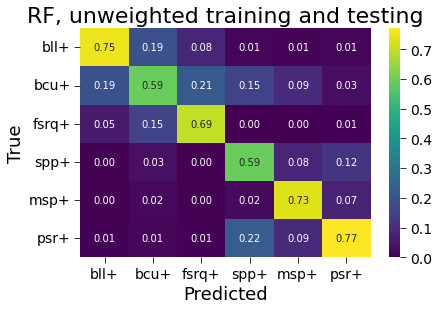

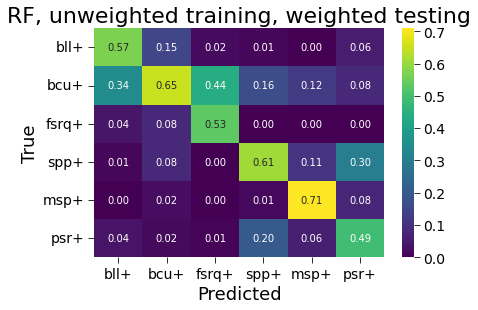

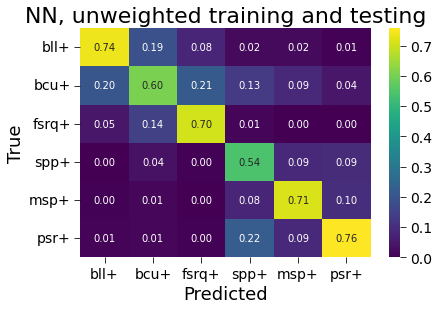

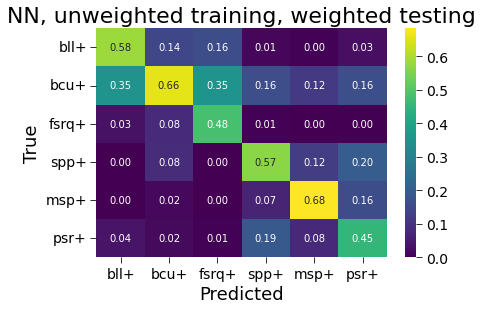

In [22]:
plots_folder = '../plots/comparisons/'
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/plots/confusion_matrix/'
save_plots = 1
save_png = 0
copy2tex = 1

single_plot_pars = {'bottom':0.12, 'left':0.15, 'right':0.99, 'top': 0.92,
                  #'axes.titlesize':18,'font.size':13
                 }

#putil.setup_figure_pars()
putil.setup_figure_pars(pars_dict=single_plot_pars)

for alg in ['RF', 'NN']:
    for weighted_test in [0, 1]:
        cm = cm_dict[alg][weighted_test]
        title = '%s, ' % alg
        alg_str = '%s_%s' % (alg, norm_dict[normalize])
        if weighted and weighted_test:
            title += 'weighted training and testing'
            fn_str = '_wtraintest_%s' % (alg_str)
        elif weighted:
            title += 'weighted training, unweighted testing'
            fn_str = '_wtrain_%s' % alg_str
        elif weighted_test:
            title += 'unweighted training, weighted testing'
            fn_str = '_wtest_%s' % alg_str
        else:
            title += 'unweighted training and testing'
            fn_str = '_%s' % alg_str

        if 1:
            fig, ax = pyplot.subplots()
            seaborn.heatmap(cm, annot=True, cmap='viridis', fmt='.2f')
            ax.set_xticklabels(labels)
            ax.set_yticklabels(labels, rotation=0)
            pyplot.xlabel('Predicted')
            pyplot.ylabel('True')
        else:
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
            disp.plot(colorbar=True)
        pyplot.title(title)

        if save_plots:
            fn = '%s/confusion_matrix%s.pdf' % (plots_folder, fn_str)
            print('save figure to file: %s' % (fn))
            pyplot.savefig(fn)
            if save_png:
                fn_png = fn.replace('.pdf', '.png')
                print('save figure to file: %s' % (fn_png))
                pyplot.savefig(fn_png)
            if copy2tex:
                fn_paper = fn.replace(plots_folder, paper_folder)
                cmd = 'cp %s %s' % (fn, fn_paper)
                print(cmd)
                os.system(cmd)